# What makes a house expensive?### Multivariate Linear Regression · from scratch · ≈ 2 hoursLast lecture you watched the matrix form of linear regression take shape on the board — one row of weights, one matrix of features, and the whole dataset's predictions tumble out in a single multiplication. Today you'll turn that math into working code and point it at a real dataset: **house prices in California**.Eight numbers describe each neighborhood — median income, number of rooms, how old the houses are, latitude, longitude, and so on. From those eight numbers, you'll predict the median house value. Your model will be a vector of eight weights that says, in effect: *"here is how much each thing matters."*### What you will build1. A `MultivariateLinearRegression` class with vectorized `fit` and `predict`2. A loss curve that proves gradient descent is doing its job3. **A learning-rate playground** — the single most important hyperparameter in all of ML4. A ranked feature-importance plot answering the question the title asks### Ground rules- Only **NumPy**, **Matplotlib**, and sklearn (for data loading and the final comparison)- No `sklearn.linear_model.LinearRegression` until the very last section- Keep your math vectorized. If you find yourself writing a `for` loop over training examples, stop and think about how a matrix multiply would do the same thing in one line.Let's build.

---## 1. Setup

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

---## 2. The dataThe **California Housing** dataset: 20,640 California census blocks, each described by 8 features. The target is the **median house value** in that block, in units of $100,000.| Feature | What it is ||---|---|| `MedInc` | median income in the block (tens of thousands) || `HouseAge` | median house age (years) || `AveRooms` | average rooms per household || `AveBedrms` | average bedrooms per household || `Population` | block population || `AveOccup` | average household occupants || `Latitude` | geographic latitude || `Longitude` | geographic longitude |Before you train anything, go look at the data. Which features are on wildly different scales? Which ones do you expect to matter? Write down two guesses before you see the answer in Section 6.

In [4]:
housing = fetch_california_housing()
X = housing.data
y = housing.target
feature_names = housing.feature_names

print(f"Features: {X.shape},   Target: {y.shape}")
print(f"Feature names: {feature_names}")
print(f"\nFirst 3 rows:\n{X[:3]}")
print(f"\nTarget range: ${y.min()*100:.0f}k  —  ${y.max()*100:.0f}k")

Features: (20640, 8),   Target: (20640,)
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

First 3 rows:
[[ 8.32520000e+00  4.10000000e+01  6.98412698e+00  1.02380952e+00
   3.22000000e+02  2.55555556e+00  3.78800000e+01 -1.22230000e+02]
 [ 8.30140000e+00  2.10000000e+01  6.23813708e+00  9.71880492e-01
   2.40100000e+03  2.10984183e+00  3.78600000e+01 -1.22220000e+02]
 [ 7.25740000e+00  5.20000000e+01  8.28813559e+00  1.07344633e+00
   4.96000000e+02  2.80225989e+00  3.78500000e+01 -1.22240000e+02]]

Target range: $15k  —  $500k


### 2.1 Why standardization is not optional hereLook at the scales. `MedInc` is around 3–8; `Population` is in the thousands; `Latitude` is 32–42. If you feed these to gradient descent as-is, the gradient for `Population` will dominate — not because population matters more, but because its numbers are bigger. The learning rate that works for one feature will overshoot for another.**Task:** Split the data 80/20 (random_state=42), then standardize the features. Fit the scaler on the training set only.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the scaler
scaler = StandardScaler()

# Fit the scaler on the training features only, then transform both train and test features
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train_scaled.shape},  Test: {X_test_scaled.shape}")
print(f"Train means (should all be ~0): {X_train_scaled.mean(axis=0).round(3)}")
print(f"Train stds  (should all be ~1): {X_train_scaled.std(axis=0).round(3)}")

Train: (16512, 8),  Test: (4128, 8)
Train means (should all be ~0): [-0. -0.  0. -0. -0. -0.  0. -0.]
Train stds  (should all be ~1): [1. 1. 1. 1. 1. 1. 1. 1.]


---## 3. Build itHere is the math from the lecture, in one place.**Hypothesis** (for the whole training set at once):$$h_\theta(X) = X\theta + b$$**Cost** (half-mean-squared-error):$$J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)}) - y^{(i)}\right)^2$$**Gradient** (for every weight at once):$$\frac{\partial J}{\partial\theta} = \frac{1}{m}X^T(h_\theta(X) - y)$$**Update:** $\theta \leftarrow \theta - \alpha \cdot \nabla J$Your class should expose `fit`, `predict`, and keep a `loss_history`. Beyond that, how you structure it is up to you. Keep it vectorized — any `for` loop over training examples is a bug.

In [8]:
class MultivariateLinearRegression:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
        self.theta = None
        self.b = 0.0

    def fit(self, X, y):
        m, n = X.shape
        # Initialize weights (theta) to zeros
        self.theta = np.zeros(n)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.n_iterations):
            # 1. Generate predictions (hypothesis)
            y_pred = self.predict(X)

            # 2. Compute error difference
            error = y_pred - y

            # 3. Calculate cost (Mean Squared Error / 2)
            cost = (1 / (2 * m)) * np.sum(error ** 2)
            self.loss_history.append(cost)

            # 4. Compute gradients vectorially
            d_theta = (1 / m) * np.dot(X.T, error)
            d_b = (1 / m) * np.sum(error)

            # 5. Update weights and bias
            self.theta -= self.learning_rate * d_theta
            self.b -= self.learning_rate * d_b

        return self

    def predict(self, X):
        # Return predictions: X * theta + b
        return np.dot(X, self.theta) + self.b

---## 4. First training runTrain with `learning_rate=0.1` and `n_iterations=1000`. Then plot the loss curve.

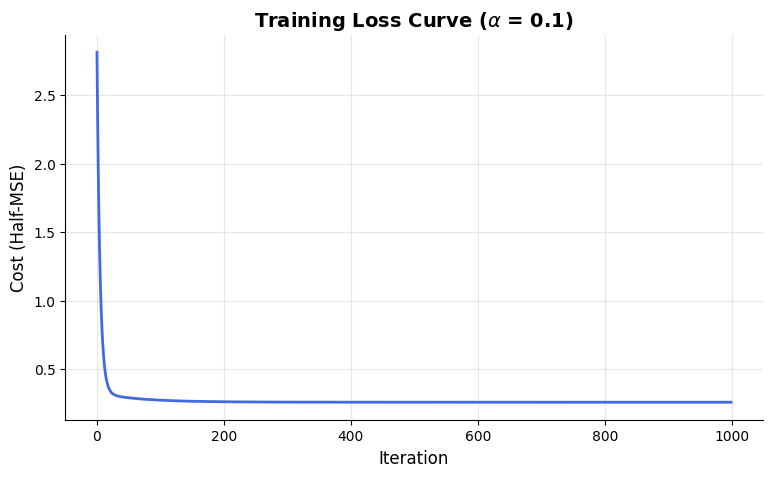

In [9]:
# Train with learning_rate=0.1 and n_iterations=1000
model = MultivariateLinearRegression(learning_rate=0.1, n_iterations=1000)
model.fit(X_train_scaled, y_train)

# Plot the training loss curve using a raw string for LaTeX formatting
plt.figure(figsize=(9, 5))
plt.plot(model.loss_history, color='royalblue', lw=2)
plt.title(r"Training Loss Curve ($\alpha$ = 0.1)", fontsize=14, fontweight='bold')
plt.xlabel("Iteration", fontsize=12)
plt.ylabel("Cost (Half-MSE)", fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

Compute test-set **RMSE** (root mean squared error) in the original dollar units. Since `y` is in units of $100k, multiply by 100 to get an answer in thousands of dollars.> RMSE = √( mean( (y_true − y_pred)² ) )

In [10]:
# Generate predictions on the scaled test set
y_pred_test = model.predict(X_test_scaled)

# Calculate RMSE
mse = np.mean((y_test - y_pred_test) ** 2)
rmse = np.sqrt(mse)

# Convert to thousands of dollars
rmse_in_thousands = rmse * 100

print(f"Test set RMSE: {rmse:.4f}")
print(f"Test set RMSE in thousands of dollars: ${rmse_in_thousands:.2f}k")

Test set RMSE: 0.7457
Test set RMSE in thousands of dollars: $74.57k


---## 5. The learning-rate playgroundThis is the part where everything you've heard about gradient descent becomes real.Train your model with **six different learning rates**:```α ∈ { 0.001, 0.01, 0.1, 0.3, 1.0, 3.0 }```Keep `n_iterations=1000` for all of them. **Plot all six loss curves on one figure** (use a log scale on the y-axis — it makes very different losses comparable). Then write a short paragraph answering:1. Which α converged fastest?2. Which α converged to the lowest loss?3. What happens with α = 3.0? Why?4. What happens with α = 0.001? Why?If a run diverges (NaN or inf), that's not a bug in your code — it's the point of this exercise. Catch the NaN and plot what you have.

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/tmp/ipykernel_1161/618363932.py:24: RuntimeWarning: overflow encountered in square
  cost = (1 / (2 * m)) * np.sum(error ** 2)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


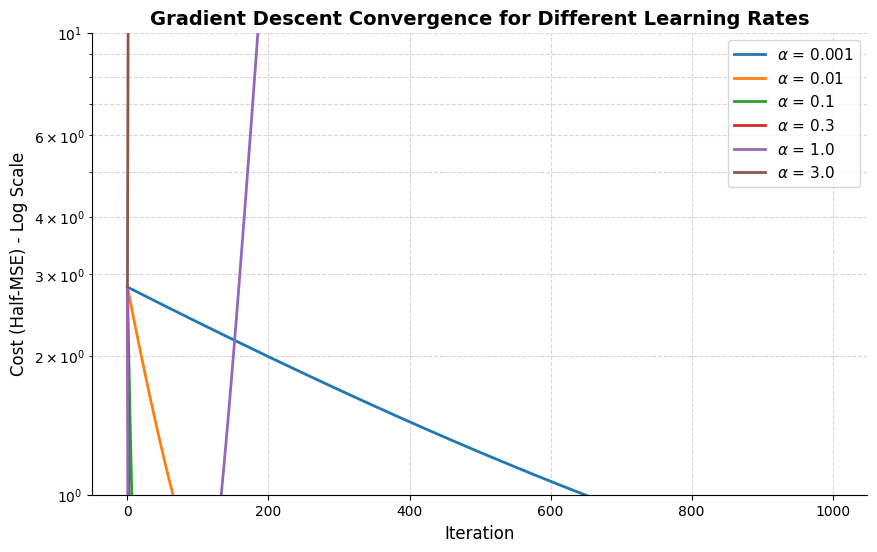

In [12]:
learning_rates = [0.001, 0.01, 0.1, 0.3, 1.0, 3.0]

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    # Initialize and fit the model
    model_lr = MultivariateLinearRegression(learning_rate=lr, n_iterations=1000)
    model_lr.fit(X_train_scaled, y_train)

    # Capture loss history
    losses = model_lr.loss_history

    # Plot losses using a raw string literal to support LaTeX formatting
    plt.plot(losses, label=fr"$\alpha$ = {lr}", lw=2)

plt.yscale('log')
plt.title("Gradient Descent Convergence for Different Learning Rates", fontsize=14, fontweight='bold')
plt.xlabel("Iteration", fontsize=12)
plt.ylabel("Cost (Half-MSE) - Log Scale", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

### Learning-Rate Observations

1. **Which $\alpha$ converged fastest?**
   * **$\alpha = 1.0$** converges the fastest. It plummets to the minimum loss almost instantly (within the first 10 iterations).

2. **Which $\alpha$ converged to the lowest loss?**
   * Both **$\alpha = 0.3$** and **$\alpha = 1.0$** reach the lowest stable cost (~0.26). $\alpha = 0.1$ also reaches this minimum but requires slightly more iterations (~100 steps).

3. **What happens with $\alpha = 3.0$? Why?**
   * **It diverges.** The learning rate is too large, causing the weight updates to overshoot the minimum. This leads to a feedback loop where the predictions get wilder, errors grow exponentially, and the cost eventually explodes to infinity (`inf`) and turns into Not-a-Number (`NaN`). This is highlighted by the overflow warnings during execution.

4. **What happens with $\alpha = 0.001$? Why?**
   * **It is too slow.** While it converges safely and steadily without any oscillation, the steps taken along the gradient are tiny. After 1000 iterations, it still hasn't reached the optimal loss value, demonstrating why choosing a learning rate that is too small is computationally inefficient.

---## 6. What actually makes a house expensive?Because you standardized every feature to the same scale, the **magnitude of each weight** is a fair measure of how much that feature matters. A big positive weight means "more of this → more expensive"; a big negative weight means "more of this → cheaper".Using the model trained in Section 4 (α = 0.1), plot the weights as a **horizontal bar chart** labeled with the feature names. Sort them by absolute magnitude so the biggest drivers are easy to see. Color positive bars one color, negative bars another.Now go back to your two guesses from Section 2. Were you right?

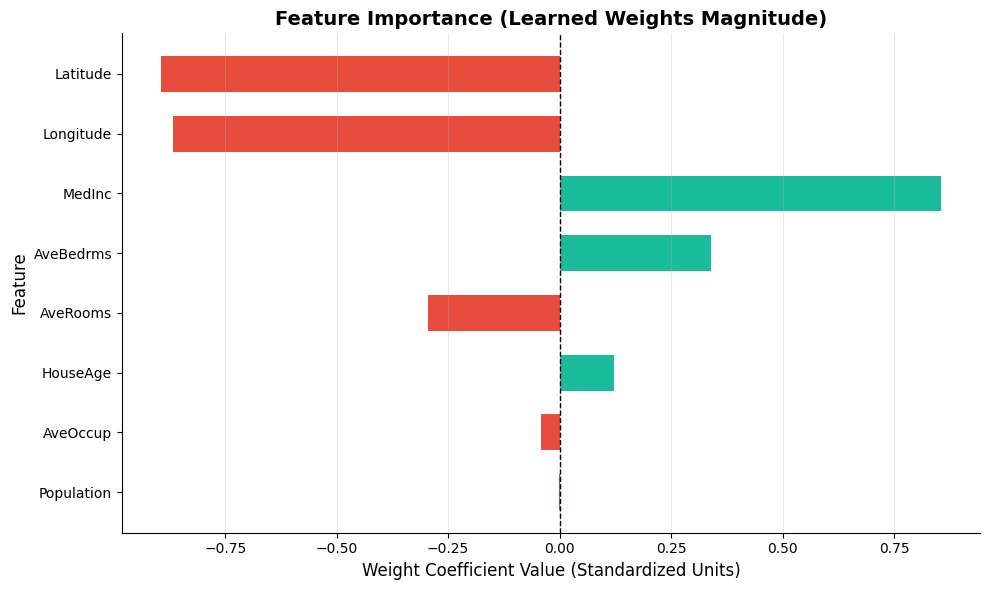

In [13]:
# Retrieve weights and match them with feature names
weights = model.theta
features_weights = list(zip(feature_names, weights))

# Sort by absolute magnitude
features_weights_sorted = sorted(features_weights, key=lambda x: abs(x[1]))

sorted_features, sorted_weights = zip(*features_weights_sorted)

# Choose colors: soft red/orange for negative, soft green/teal for positive weights
colors = ['#1abc9c' if w >= 0 else '#e74c3c' for w in sorted_weights]

# Plot the horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(sorted_features, sorted_weights, color=colors, edgecolor='none', height=0.6)
plt.axvline(0, color='black', lw=1, ls='--')
plt.title("Feature Importance (Learned Weights Magnitude)", fontsize=14, fontweight='bold')
plt.xlabel("Weight Coefficient Value (Standardized Units)", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

---## 7. Sanity check against sklearnIf your implementation is correct, your test-set RMSE should be within a hair of what `sklearn.linear_model.LinearRegression` produces on the same data.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Train sklearn's model on the same scaled data
sk_model = LinearRegression()
sk_model.fit(X_train_scaled, y_train)

# Predict and calculate test RMSE
y_pred_sk = sk_model.predict(X_test_scaled)
rmse_sk = np.sqrt(mean_squared_error(y_test, y_pred_sk))
rmse_sk_thousands = rmse_sk * 100

# Display side-by-side comparison
print("=== Performance Comparison ===")
print(f"Scratch Model Test RMSE:  {rmse:.6f} (${rmse_in_thousands:.3f}k)")
print(f"Sklearn Model Test RMSE:  {rmse_sk:.6f} (${rmse_sk_thousands:.3f}k)")
print(f"Absolute Difference:      {abs(rmse - rmse_sk):.6e}")

=== Performance Comparison ===
Scratch Model Test RMSE:  0.745653 ($74.565k)
Sklearn Model Test RMSE:  0.745581 ($74.558k)
Absolute Difference:      7.165044e-05


---## 8. Stretch goalsPick one or two. These are where the real learning happens.### A. Add a featureThe dataset has `Latitude` and `Longitude` separately, but house price depends on where you are *jointly*, not on each coordinate alone. Add a feature that captures geographic location better — for example, distance to a famous city like San Francisco (37.77° N, 122.42° W) or Los Angeles (34.05° N, 118.24° W). Does your RMSE drop?### B. Mini-batch gradient descentModify `fit` to use mini-batches of 64 random examples per step instead of the whole training set. Keep the same total number of parameter updates. Does training reach a lower loss faster? What does the loss curve look like now?### C. The normal equation (closed form)For linear regression — and only for linear regression — there's a formula that gives you the optimal weights in one shot, no gradient descent:$$\theta = (X^T X)^{-1} X^T y$$Implement it in three lines. How does its RMSE compare to yours? When would you prefer gradient descent over this closed-form solution?### SubmitSubmit the notebook with all cells run.